# 05 · Temporal validation, tuning and leakage experiments

Reads the output of `fraud models tune` (`data/processed/phase7/`). Training window
2024-10-01 → 2025-06-30, split into four expanding folds (test months March to June 2025,
14-day gap before each). Validation (Jul–Sep 2025) is only used to confirm choices made with
cross-validation. The test period is not loaded.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from fraudplatform.config import PROJECT_ROOT, load_model_config
from fraudplatform.eda import plots

plots.apply_style()
pd.set_option("display.width", 160)
run_dir = PROJECT_ROOT / "data" / "processed" / "phase7"
results = json.loads((run_dir / "results.json").read_text(encoding="utf-8"))
cfg = load_model_config()
pd.DataFrame(results["folds"])

,fold,train_end,train_rows,test_rows,test_frauds
0,test 2025-03,2025-02-15,511153,115608,954
1,test 2025-04,2025-03-18,625182,113139,1035
2,test 2025-05,2025-04-17,737986,118711,1038
3,test 2025-06,2025-05-18,856274,114314,1197


## 1. H7: does shuffled cross-validation overstate performance?

Same model (gradient boosting, Phase 6 defaults), same rows, two ways of splitting them.
Shuffled K-fold lets the model train on transactions from the *future* of the ones it is
tested on, and puts transactions of the same fraud campaign on both sides of the split.
The out-of-time validation score (a model trained on the whole window and scored on the
next three months) is the closest offline estimate of real deployment.

,temporal fold PR-AUC,random fold PR-AUC
test 2025-03,0.8115,0.8103
test 2025-04,0.7678,0.8184
test 2025-05,0.7951,0.8249
test 2025-06,0.8215,0.8138


,PR-AUC
temporal CV mean,0.7990
random CV mean,0.8169
validation (out of time),0.7901


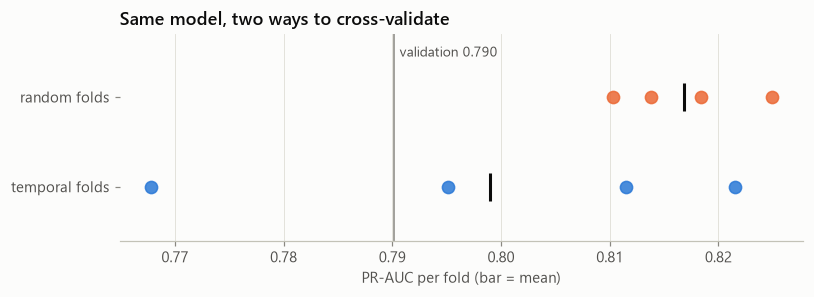

In [2]:
h7 = results["h7"]
h7_table = pd.DataFrame(
    {
        "temporal fold PR-AUC": h7["temporal_folds"],
        "random fold PR-AUC": h7["random_folds"],
    },
    index=[f["fold"] for f in results["folds"]],
)
display(h7_table.style.format("{:.4f}"))
summary = pd.Series(
    {
        "temporal CV mean": np.mean(h7["temporal_folds"]),
        "random CV mean": np.mean(h7["random_folds"]),
        "validation (out of time)": h7["validation_out_of_time"],
    }
)
display(summary.to_frame("PR-AUC").style.format("{:.4f}"))

fig, ax = plt.subplots(figsize=(7.5, 2.8))
for i, (_label, values, color) in enumerate(
    [
        ("temporal folds", h7["temporal_folds"], plots.BLUE),
        ("random folds", h7["random_folds"], plots.ORANGE),
    ]
):
    ax.plot(values, [i] * len(values), "o", color=color, markersize=8, alpha=0.85)
    ax.plot(np.mean(values), i, "|", color=plots.INK, markersize=18, markeredgewidth=2)
ax.axvline(h7["validation_out_of_time"], color=plots.MUTED, linewidth=1)
ax.annotate(
    f"validation {h7['validation_out_of_time']:.3f}",
    (h7["validation_out_of_time"], 1.45),
    xytext=(4, 0),
    textcoords="offset points",
    color=plots.INK_SECONDARY,
    fontsize=9,
)
ax.set_yticks([0, 1], ["temporal folds", "random folds"])
ax.set_ylim(-0.6, 1.7)
ax.grid(axis="y", visible=False)
ax.set_xlabel("PR-AUC per fold (bar = mean)")
ax.set_title("Same model, two ways to cross-validate")
fig.tight_layout()
plots.save(fig, "h7_random_vs_temporal", folder="models")
plt.show()

## 2. Logistic regression: grid over the regularisation strength C

In [3]:
lr = pd.read_csv(run_dir / "lr_cv_results.csv")
lr.style.format({c: "{:.4f}" for c in lr.columns if "score" in c or "time" in c})

,param_model__C,split0_test_score,split1_test_score,split2_test_score,split3_test_score,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,10.000000,0.7853,0.7504,0.7916,0.8165,0.7859,0.0236,27.7744,1.0000
1,100.000000,0.7844,0.7505,0.7910,0.8163,0.7855,0.0235,32.7279,2.0000
2,1.000000,0.7849,0.7501,0.7909,0.8161,0.7855,0.0236,26.5200,3.0000
3,0.100000,0.7849,0.7491,0.7900,0.8154,0.7849,0.0236,29.9201,4.0000
4,0.010000,0.7849,0.7486,0.7851,0.8133,0.7830,0.0230,29.9349,5.0000


## 3. Gradient boosting: randomized search (16 candidates × 4 temporal folds)

Search space (`configs/model.yaml`): learning rate log-uniform 0.02–0.2, iterations
{200, 400, 800}, leaves {15, 31, 63, 127}, min samples per leaf {20, 50, 100, 200}, L2
log-uniform 0.001–10, share of features per split {0.5, 0.8, 1.0}. Metric: PR-AUC.

In [4]:
hgb = pd.read_csv(run_dir / "hgb_cv_results.csv")
hgb.head(10).style.format(
    {c: "{:.4f}" for c in hgb.columns if "score" in c}
    | {
        "param_model__learning_rate": "{:.3f}",
        "param_model__l2_regularization": "{:.3f}",
        "mean_fit_time": "{:.0f}",
    }
)

,param_model__l2_regularization,param_model__learning_rate,param_model__max_features,param_model__max_iter,param_model__max_leaf_nodes,param_model__min_samples_leaf,split0_test_score,split1_test_score,split2_test_score,split3_test_score,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,0.680,0.021,0.800000,400,31,50,0.8142,0.7629,0.8068,0.8299,0.8034,0.0249,15,1.0000
1,7.853,0.034,0.800000,800,31,100,0.8090,0.7716,0.7962,0.8282,0.8012,0.0206,27,2.0000
2,0.005,0.031,0.800000,400,15,200,0.8041,0.7609,0.8083,0.8272,0.8001,0.0242,12,3.0000
3,0.037,0.030,0.800000,400,31,50,0.8097,0.7607,0.8007,0.8278,0.7997,0.0246,14,4.0000
4,0.154,0.031,1.000000,400,31,200,0.8145,0.7618,0.7968,0.8258,0.7997,0.0242,14,5.0000
5,1.712,0.040,0.500000,400,127,200,0.8079,0.7645,0.7928,0.8275,0.7982,0.0230,24,6.0000
6,0.061,0.025,1.000000,200,127,200,0.8091,0.7625,0.7888,0.8297,0.7975,0.0249,13,7.0000
7,0.526,0.056,0.800000,200,127,50,0.8116,0.7553,0.7961,0.8261,0.7973,0.0264,12,8.0000
8,0.058,0.026,0.500000,800,63,50,0.8084,0.7617,0.7953,0.8235,0.7972,0.0228,29,9.0000
9,0.002,0.031,0.500000,400,127,20,0.8041,0.7618,0.7986,0.8224,0.7967,0.0220,21,10.0000


In [5]:
spread = hgb["mean_test_score"].agg(["max", "median", "min"])
print(
    f"16 candidates: best {spread['max']:.4f}, median {spread['median']:.4f}, "
    f"worst {spread['min']:.4f}"
)
print(
    f"default configuration through the same folds: "
    f"{results['default_hgb']['cv_temporal_mean']:.4f}"
)

16 candidates: best 0.8034, median 0.7972, worst 0.6018
default configuration through the same folds: 0.7990


## 4. Do the tuned models beat the defaults on validation?

In [6]:
rows = []
for name, label in [
    ("default_hgb", "gradient boosting, Phase 6 defaults"),
    ("hist_gradient_boosting", "gradient boosting, tuned"),
    ("logistic_regression", "logistic regression, tuned"),
]:
    r = results[name]
    v = r["validation"]
    rows.append(
        {
            "model": label,
            "cv PR-AUC": r.get("cv_best", r.get("cv_temporal_mean")),
            "validation PR-AUC": v["pr_auc"],
            "precision @0.5%": v["precision_at_alert_rate"],
            "recall @0.5%": v["recall_at_alert_rate"],
            "brier": v["brier"],
            "best params": r.get("best_params", ""),
        }
    )
display(
    pd.DataFrame(rows).style.format(
        {
            "cv PR-AUC": "{:.4f}",
            "validation PR-AUC": "{:.4f}",
            "precision @0.5%": "{:.1%}",
            "recall @0.5%": "{:.1%}",
            "brier": "{:.5f}",
        }
    )
)
paired = pd.DataFrame(
    {
        name: results[name]["vs_default_hgb_on_validation"]
        for name in ["hist_gradient_boosting", "logistic_regression"]
    }
).T
paired.style.format(
    {"difference": "{:+.4f}", "ci_low": "{:+.4f}", "ci_high": "{:+.4f}", "share_a_better": "{:.1%}"}
).set_caption(
    "Paired day-block bootstrap on validation: tuned model minus default gradient boosting"
)

,model,cv PR-AUC,validation PR-AUC,precision @0.5%,recall @0.5%,brier,best params
0,"gradient boosting, Phase 6 defaults",0.7990,0.7901,91.8%,63.2%,0.00231,
1,"gradient boosting, tuned",0.8034,0.7940,91.7%,63.2%,0.00225,"{'l2_regularization': 0.679657809075816, 'learning_rate': 0.02097077545038924, 'max_features': 0.8, 'max_iter': 400, 'max_leaf_nodes': 31, 'min_samples_leaf': 50}"
2,"logistic regression, tuned",0.7859,0.7662,88.3%,60.9%,0.00263,{'C': 10.0}


,difference,ci_low,ci_high,share_a_better
hist_gradient_boosting,+0.0039,-0.0008,+0.0097,93.0%
logistic_regression,-0.0239,-0.0333,-0.0152,0.0%


## 5. H8: how much do leaky features inflate the offline numbers?

The model is trained with the five deliberately leaky features in place of their clean
counterparts. Offline, validation can be computed with leaky values too, because the
extract already contains the future. In production the future does not exist: the only
values the scoring service can compute are the point-in-time ones, so that is what the
model would receive.

,PR-AUC
clean features: temporal CV,0.7990
leaky features: temporal CV,0.8688
clean features: validation,0.7901
"leaky features: validation, leaky values (offline report)",0.8521
"leaky features: validation, values available at decision time (production)",0.4007


served leaky model minus clean model (paired bootstrap): {'difference': -0.38940598192398035, 'ci_low': -0.41401772097076583, 'ci_high': -0.3645091506072798, 'share_a_better': 0.0}


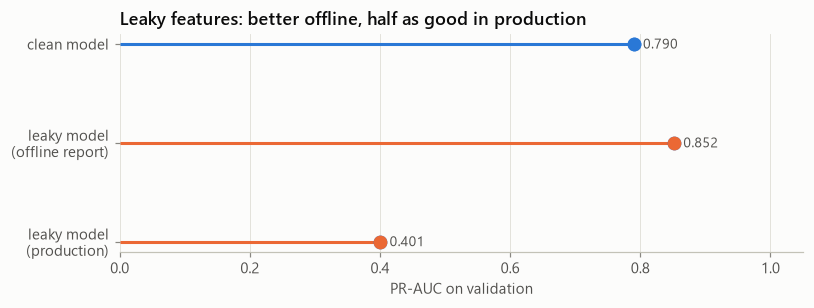

In [7]:
h8 = results["h8"]
h8_table = pd.Series(
    {
        "clean features: temporal CV": h8["clean_cv_temporal_mean"],
        "leaky features: temporal CV": h8["leaky_cv_temporal_mean"],
        "clean features: validation": h8["clean_validation"],
        "leaky features: validation, leaky values (offline report)": h8["leaky_validation_offline"],
        "leaky features: validation, values available at decision time (production)": h8[
            "leaky_validation_served"
        ],
    }
)
display(h8_table.to_frame("PR-AUC").style.format("{:.4f}"))
print("served leaky model minus clean model (paired bootstrap):", h8["served_vs_clean"])

fig, ax = plt.subplots(figsize=(7.5, 2.9))
labels = ["clean model", "leaky model\n(offline report)", "leaky model\n(production)"]
values = [h8["clean_validation"], h8["leaky_validation_offline"], h8["leaky_validation_served"]]
colors = [plots.BLUE, plots.ORANGE, plots.ORANGE]
y = np.arange(len(labels))[::-1]
ax.hlines(y, 0, values, color=colors, linewidth=2)
ax.plot(values, y, "o", color=plots.BLUE, markersize=8)
for yi, v, c in zip(y, values, colors, strict=True):
    ax.plot(v, yi, "o", color=c, markersize=8)
    ax.annotate(
        f"{v:.3f}",
        (v, yi),
        xytext=(6, -3),
        textcoords="offset points",
        color=plots.INK_SECONDARY,
        fontsize=9,
    )
ax.set_yticks(y, labels)
ax.set_xlim(0, 1.05)
ax.grid(axis="y", visible=False)
ax.set_xlabel("PR-AUC on validation")
ax.set_title("Leaky features: better offline, half as good in production")
fig.tight_layout()
plots.save(fig, "h8_leaky_features", folder="models")
plt.show()

## 6. Findings

Full write-up: [`reports/models/phase7_findings.md`](../reports/models/phase7_findings.md).

- **H7 supported, modestly:** shuffled CV 0.817 vs temporal CV 0.799 vs out-of-time
  validation 0.790. The bigger lesson is the month-to-month spread (0.768 to 0.822).
- **Tuning is within noise:** best gradient boosting 0.803 in CV vs 0.799 default; on
  validation +0.004 (CI −0.001 to +0.010). 13 of 16 candidates sit between 0.795 and 0.803.
  Kept as the selected model (chosen by CV), but the defaults were already near-optimal.
- **H8 supported, dramatically:** leaky features score 0.852 offline and 0.401 with the
  values available in production, half as good as the honest model.

Re-run in Phase 13 with a fixed row order; the original numbers are in section 5 of the
findings.